In [1]:
import os

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

import pandas as pd
import numpy as np
import statistics
import plotnine as p9
from imml.visualize import plot_combinations, plot_summary
from imml.impute import get_observed_mod_indicator
from scipy.stats import chi2_contingency
from plotnine.composition import plot_spacer
from statsmodels.stats.multitest import multipletests
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.plotting import add_at_risk_counts
from lifelines.statistics import multivariate_logrank_test, logrank_test
from lifelines.utils import restricted_mean_survival_time
import copy
from matplotlib_venn import venn2
from matplotlib import pyplot as plt
from plotnine.composition import plot_spacer

from src.clustering.utils import get_Xs_ids, prepare_Xs
from src.clustering.clinical_relevance_clusters import get_p_rmst
from src.clustering.settings import best_pipeline, discrete_clinical_variables, clinical_endpoints, final_cluster_name, rename_cols_dict, timepoints

plt.rcParams['svg.fonttype'] = 'none'

In [2]:
eval_cols = ["LLM", "Algorithm", "Clusters"]
comp_metrics = ["General performance score", "Stability", "Total Silhouette"]
clinical_endpoints_description = [val["description"] for val in clinical_endpoints.values()]
discrete_clinical_variables = [rename_cols_dict[val] for val in discrete_clinical_variables]

In [3]:
merge_cols = eval_cols + ["Incomplete samples (%)", "Strategy"]
embedding_clusters_amputation = os.path.join("results_v2_permodality", "clustering", "embedding_clusters_amputation.csv")
embedding_clusters_amputation = pd.read_csv(embedding_clusters_amputation)
reduced_embedding_clusters_amputation = embedding_clusters_amputation.groupby(merge_cols, as_index=False)[comp_metrics[-1]].mean()
print(f"{embedding_clusters_amputation.shape=}")
print(f"{reduced_embedding_clusters_amputation.shape=}")
embedding_clusters_amputation.head()

embedding_clusters_amputation.shape=(1050, 12)
reduced_embedding_clusters_amputation.shape=(21, 6)


,LLM,Algorithm,Clusters,Strategy,Incomplete samples (%),Fold,IDs,Labels,Total Silhouette,Reduced Silhouette,N,M
0,smb8b_qwen3_mo,NEMO,2,Complete,0.8,0,"['1410950', '277917', '857282', '1237993', '63...",[0 1 0 0 1 1 1 0 1 1 1 1 1 1 0 0 0 1 1 0 0 0 1...,0.802306,0.802306,76,4096
1,smb8b_qwen3_mo,NEMO,2,Complete,0.8,1,"['1078774', '581492', '438752', '1203807', '14...",[1 0 1 1 0 1 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 1...,0.893011,0.893011,76,4096
2,smb8b_qwen3_mo,NEMO,2,Complete,0.8,2,"['1130580', '884999', '924048', '1472524', '14...",[1 0 1 1 0 0 1 0 0 0 1 0 0 1 0 0 1 0 0 0 1 0 1...,0.747736,0.747736,76,4096
3,smb8b_qwen3_mo,NEMO,2,Complete,0.8,3,"['484722', '1442355', '1230627', '421857', '14...",[1 1 1 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1 0 0 1 1 0...,0.831142,0.831142,76,4096
4,smb8b_qwen3_mo,NEMO,2,Complete,0.8,4,"['1237993', '313421', '752181', '1192207', '98...",[1 1 1 0 0 0 1 1 1 1 1 0 1 1 1 1 0 1 0 1 1 1 0...,0.815330,0.815330,76,4096


In [4]:
cluster_robustness = os.path.join("results_v2_permodality", "clustering", "cluster_robustness.csv")
cluster_robustness = pd.read_csv(cluster_robustness)
cluster_robustness["AMIs"] = cluster_robustness["AMIs"].apply(eval)
cluster_robustness["Robustness_var"] = cluster_robustness["AMIs"].apply(np.var)
print(f"{cluster_robustness.shape=}")
cluster_robustness.head()

cluster_robustness.shape=(25, 9)


,LLM,Algorithm,Clusters,Strategy,Incomplete samples (%),Folds,AMIs,Robustness,Robustness_var
0,smb8b_qwen3_mo,NEMO,2,All,0.0,50,"[1.0, 1.0, 1.0, 0.9697523591452014, 1.0, 0.969...",0.981239,0.000370
1,smb8b_qwen3_mo,NEMO,2,Complete,0.2,50,"[1.0, 1.0, 1.0, 0.9637194834075833, 1.0, 0.963...",0.973827,0.000944
2,smb8b_qwen3_mo,NEMO,2,Complete,0.4,50,"[1.0, 1.0, 1.0, 0.9534109995295433, 1.0, 0.953...",0.963481,0.001631
3,smb8b_qwen3_mo,NEMO,2,Complete,0.6,50,"[0.9437817090837604, 0.9327089198998385, 1.0, ...",0.933747,0.003664
4,smb8b_qwen3_mo,NEMO,2,Complete,0.8,50,"[0.9019175299772686, 0.8864815844866433, 1.0, ...",0.900453,0.008978


In [5]:
cluster_robustness_wide = cluster_robustness.explode('AMIs')
cluster_robustness_wide = cluster_robustness_wide.merge(embedding_clusters_amputation, on=merge_cols, validate="many_to_many")
cluster_robustness_wide = pd.concat([
    cluster_robustness_wide,
    *[cluster_robustness_wide[cluster_robustness_wide["Incomplete samples (%)"] == 0].replace({"Strategy": "All"}, strategy)
      for strategy in cluster_robustness_wide["Strategy"].unique() if strategy != "All"]
])
print(f"{cluster_robustness_wide.shape=}")
cluster_robustness_wide.head()

cluster_robustness_wide.shape=(3125000, 16)


,LLM,Algorithm,Clusters,Strategy,Incomplete samples (%),Folds,AMIs,Robustness,Robustness_var,Fold,IDs,Labels,Total Silhouette,Reduced Silhouette,N,M
0,smb8b_qwen3_mo,NEMO,2,All,0.0,50,1.0,0.981239,0.00037,0,"['1410950', '1402243', '307869', '277917', '10...",[1 1 0 0 1 1 0 1 1 1 1 1 0 1 1 0 0 1 0 1 0 1 0...,0.825439,0.825439,382,4096
1,smb8b_qwen3_mo,NEMO,2,All,0.0,50,1.0,0.981239,0.00037,1,"['1078774', '875152', '505630', '330399', '745...",[0 1 0 1 1 1 0 0 0 0 1 1 1 1 1 1 0 0 1 1 0 1 1...,0.838808,0.838808,382,4096
2,smb8b_qwen3_mo,NEMO,2,All,0.0,50,1.0,0.981239,0.00037,2,"['1384866', '998834', '742863', '210505', '123...",[0 1 0 0 0 0 0 1 1 0 1 1 0 0 0 1 1 1 0 0 1 0 0...,0.816850,0.816850,382,4096
3,smb8b_qwen3_mo,NEMO,2,All,0.0,50,1.0,0.981239,0.00037,3,"['277917', '112340', '1239735', '484722', '144...",[0 0 0 1 1 0 0 1 0 1 1 1 1 0 0 1 1 0 1 1 1 0 1...,0.826952,0.826952,382,4096
4,smb8b_qwen3_mo,NEMO,2,All,0.0,50,1.0,0.981239,0.00037,4,"['1406838', '521644', '1044448', '330399', '12...",[0 0 0 0 0 1 0 0 0 0 0 1 1 1 1 0 0 1 0 1 0 0 0...,0.815167,0.815167,382,4096


In [6]:
cluster_robustness = cluster_robustness.merge(reduced_embedding_clusters_amputation, on=merge_cols, validate="one_to_one")
cluster_robustness = pd.concat([
    cluster_robustness,
    *[cluster_robustness[cluster_robustness["Incomplete samples (%)"] == 0].replace({"Strategy": "All"}, strategy)
      for strategy in cluster_robustness["Strategy"].unique() if strategy != "All"]
])
cluster_robustness["General performance score"] = cluster_robustness[["Robustness", comp_metrics[-1]]].clip(lower=0).apply(statistics.harmonic_mean, axis=1)
print(f"{cluster_robustness.shape=}")
cluster_robustness.head()

cluster_robustness.shape=(25, 11)


,LLM,Algorithm,Clusters,Strategy,Incomplete samples (%),Folds,AMIs,Robustness,Robustness_var,Total Silhouette,General performance score
0,smb8b_qwen3_mo,NEMO,2,All,0.0,50,"[1.0, 1.0, 1.0, 0.9697523591452014, 1.0, 0.969...",0.981239,0.000370,0.819397,0.893044
1,smb8b_qwen3_mo,NEMO,2,Complete,0.2,50,"[1.0, 1.0, 1.0, 0.9637194834075833, 1.0, 0.963...",0.973827,0.000944,0.820510,0.890619
2,smb8b_qwen3_mo,NEMO,2,Complete,0.4,50,"[1.0, 1.0, 1.0, 0.9534109995295433, 1.0, 0.953...",0.963481,0.001631,0.820484,0.886252
3,smb8b_qwen3_mo,NEMO,2,Complete,0.6,50,"[0.9437817090837604, 0.9327089198998385, 1.0, ...",0.933747,0.003664,0.816362,0.871118
4,smb8b_qwen3_mo,NEMO,2,Complete,0.8,50,"[0.9019175299772686, 0.8864815844866433, 1.0, ...",0.900453,0.008978,0.812737,0.854349


In [7]:
cluster_robustness = cluster_robustness[cluster_robustness["Strategy"].ne("Complete") & cluster_robustness["Incomplete samples (%)"].gt(0)]
cluster_robustness["Incomplete samples (%)"] = cluster_robustness["Incomplete samples (%)"].mul(100)
cluster_robustness["Strategy"] = cluster_robustness["Strategy"].replace({
    "All": "NEMO",
    "Mean Imputation": "Mean Imputation + NEMO",
    "Median Imputation": "Median Imputation + NEMO",
    "KNN Imputation": "KNN Imputation + NEMO",
})

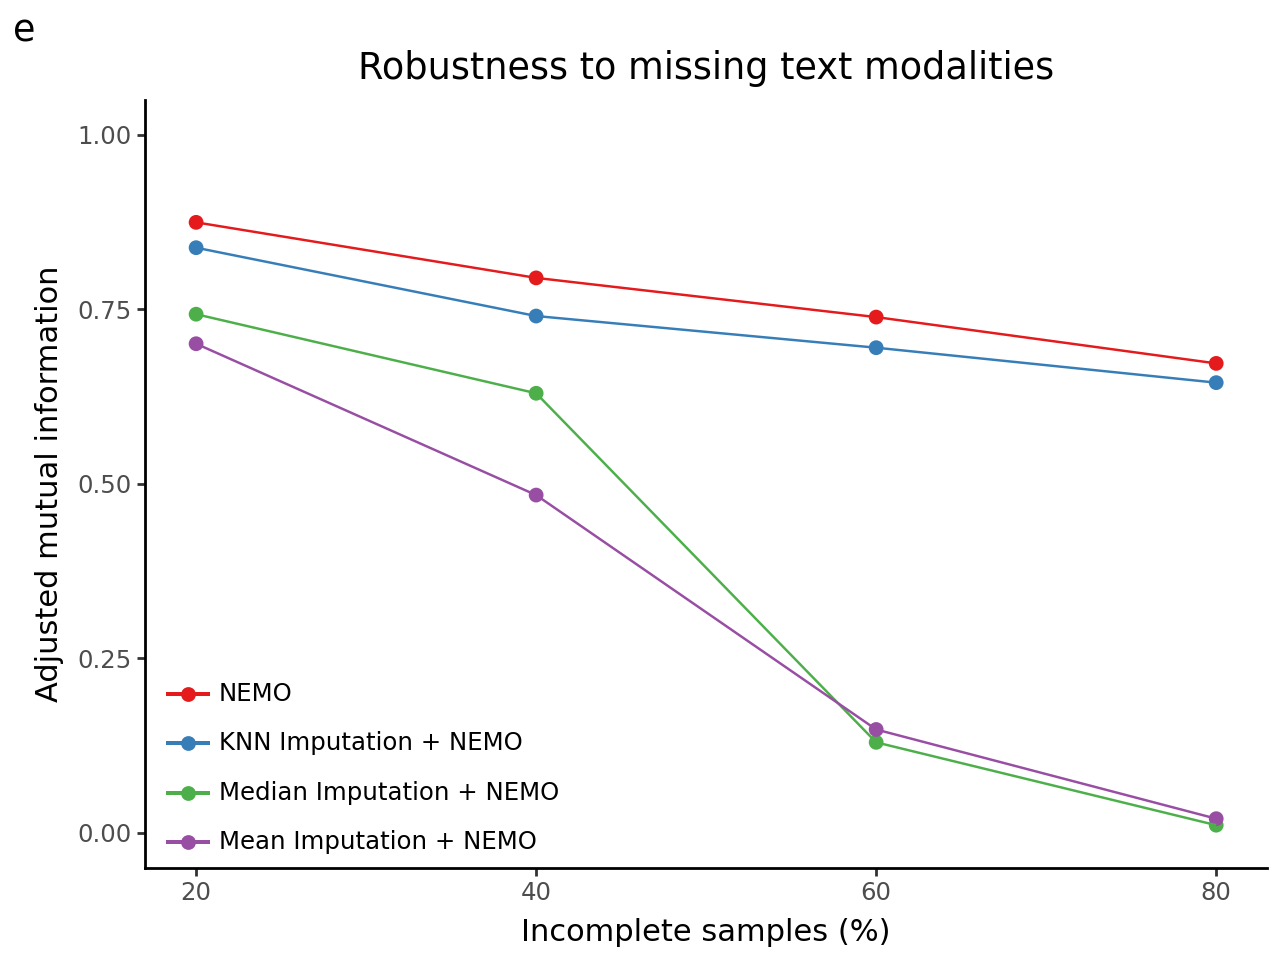

In [8]:
x,y = "Incomplete samples (%)", "Robustness"
fill_by = "Strategy"
custom_order = cluster_robustness.groupby(fill_by, as_index=False)[y].mean().sort_values(y, ascending=False)[fill_by].unique().tolist()
cluster_robustness[fill_by] = pd.Categorical(cluster_robustness[fill_by], categories=custom_order, ordered=True)

p_rob = (
    p9.ggplot(cluster_robustness, p9.aes(x=x, y=y, fill=fill_by, color=fill_by))
    + p9.stat_summary(fun_data='mean_cl_boot', geom='pointrange')
    + p9.geom_line()
    + p9.theme_classic()
    + p9.theme(legend_position="inside", legend_position_inside=(0.025, 0.001), legend_title=p9.element_blank(), legend_background=p9.element_blank())
    + p9.ylim((0,1))
    + p9.scale_fill_brewer(type="qualitative", palette="Set1", direction=1)
    + p9.scale_color_brewer(type="qualitative", palette="Set1", direction=1)
    + p9.labs(tag="e", y="Adjusted mutual information", title= "Robustness to missing text modalities")
)
p_rob

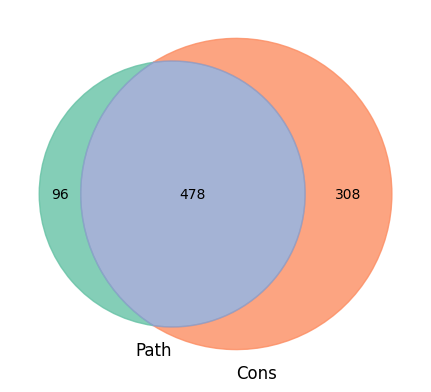

In [9]:
Xs = get_Xs_ids(llm=best_pipeline["llm"])[0]
Xs = prepare_Xs(Xs)

observed_mod_indicator = get_observed_mod_indicator(Xs).astype(int)
observed_mod_indicator = observed_mod_indicator.iloc[:, 0].sub(observed_mod_indicator.iloc[:, 1]).replace({
    -1: "Cons",
    0: "Complete",
    1: "Path",
})

v = observed_mod_indicator.value_counts().sort_values()
v = venn2(subsets = v, set_labels = v.index)

set2_colors = plt.cm.get_cmap('Set2').colors[:3]
if v.get_patch_by_id('10'): v.get_patch_by_id('10').set_color(set2_colors[0])
if v.get_patch_by_id('01'): v.get_patch_by_id('01').set_color(set2_colors[1])
if v.get_patch_by_id('11'): v.get_patch_by_id('11').set_color(set2_colors[2])

for patch in [v.get_patch_by_id('10'), v.get_patch_by_id('01'), v.get_patch_by_id('11')]:
    if patch: patch.set_alpha(0.8)


plt.savefig(os.path.join("figures", "Figure3a.svg"), bbox_inches='tight')
plt.show()

In [10]:
# observed_mod_indicator = get_observed_mod_indicator(Xs).astype(int)
# observed_mod_indicator = observed_mod_indicator.iloc[:, 0].sub(observed_mod_indicator.iloc[:, 1]).replace({
#     -1: "Notes",
#     0: "Complete",
#     1: "Pathology",
# })
# p_count = (
#     p9.ggplot(observed_mod_indicator.to_frame(name="a"), p9.aes(x="a", fill="a")) 
#     + p9.geom_bar()
#     + p9.geom_text(
#         p9.aes(label=p9.after_stat("count")), 
#         stat="count", 
#         nudge_y=0.25, 
#         va="bottom"
#     )
#     + p9.scale_fill_brewer(type="qualitative", palette="Set2", direction=-1)
#     + p9.theme_classic()
#     + p9.theme(axis_title_x=p9.element_blank(), legend_position="none")
#     + p9.labs(x="", y="Patients", tag="b", fill="Available", title="Availability text modalities")
# )
# p_count

In [11]:
clinical_data = os.path.join("outcomes", "all_fields_processed.csv")
clinical_data = pd.read_csv(clinical_data)
clinical_data = clinical_data.rename(columns=rename_cols_dict)
print(f"{clinical_data.shape=}")
clinical_data.head()

clinical_data.shape=(857, 95)


,patient_id,Anatomic_Site_of_Lesion,Pathological_TNM,Clinical_TNM,Primary_Tumor_Size,Tumor_Type_Differentiation,Pathology_Details,Lymph_Node_Status_Presence_Absence,Lymph_Node_Status_Number_of_Positve_Lymph_Nodes,Lymph_Node_Status_Extranodal_Extension,...,Differentiation,LN_Involvement,Num_Positive_Nodes,Anatomic_Site,Tumor_Size,ECOG_Status,CCS_Category,T-stage,N-stage,Pack_Years_Category
0,6369,"Right parotid gland, salivary gland tumor with...",Not inferred,Not inferred,2.6x2.2 cm,Not Inferred,Fragments of salivary gland tumor with basaloi...,Not inferred,Not inferred,Not inferred,...,NaN,NaN,NaN,Salivary,2-4cm,NaN,CCS 2+,NaN,NaN,Never (0)
1,7777,"left nasal ala, Merkel cell carcinoma",Not inferred,T1 N0 M0,0.3 x 0.3 x 0.2 cm,Not Inferred,"Merkel cell carcinoma, tumor cells react with ...",Absent,0,Absent,...,NaN,Negative,N0,Sinonasal,≤2cm,ECOG 0,CCS 0-1,T0-1,N0,Never (0)
2,9131,"Left pyriform sinus, invasive squamous cell ca...",Not inferred,T3 N1,3.5 x 2.0 x 1.7 cm,Moderately differentiated,"Invasive squamous cell carcinoma, moderately d...",Present,1,Not inferred,...,Moderate,Positive,N1-2,Hypopharynx,≤2cm,ECOG 0,CCS 2+,T3,N1,Heavy (>40)
3,12144,"base of tongue, squamous cell carcinoma",Not inferred,"T3, N2c, Mx",5 to 6 cm in diameter,Poorly differentiated,invasive poorly differentiated squamous cell c...,Present,Not inferred (multiple bilateral pathological ...,Not inferred,...,Poor,Positive,NaN,Oropharynx,>4cm,ECOG 0,CCS 2+,T3,N2-3,NaN
4,13428,"right lateral border of tongue, Mixed verrucou...",Not inferred,T2 Nx M0,3-4 cm,Well differentiated,Mixed verrucous carcinoma and invasive well-di...,Suspected,1 {indeterminate left level Ib lymph node},Not inferred,...,Well,NaN,N1-2,Oral Cavity,2-4cm,ECOG 0,CCS 2+,T2,NaN,Never (0)


In [12]:
embedding_clusters = os.path.join("results_v2_permodality", "clustering", "embedding_clusters.csv")
embedding_clusters = pd.read_csv(embedding_clusters, index_col=0)[best_pipeline["name"]].replace({0: "Low-risk", 1: "High-risk"}) \
    .astype(object).squeeze().rename(final_cluster_name)
embedding_clusters.index = embedding_clusters.index.astype(int)
clinical_data_with_clusters = clinical_data.merge(embedding_clusters, left_on="patient_id", right_index=True)
observed_mod_indicator.index = observed_mod_indicator.index.astype(int)
clinical_data_with_clusters = clinical_data_with_clusters.merge(observed_mod_indicator.rename("Available"), left_on="patient_id", right_index=True)
print(f"{clinical_data.shape=}")
clinical_data.head()

clinical_data.shape=(857, 95)


,patient_id,Anatomic_Site_of_Lesion,Pathological_TNM,Clinical_TNM,Primary_Tumor_Size,Tumor_Type_Differentiation,Pathology_Details,Lymph_Node_Status_Presence_Absence,Lymph_Node_Status_Number_of_Positve_Lymph_Nodes,Lymph_Node_Status_Extranodal_Extension,...,Differentiation,LN_Involvement,Num_Positive_Nodes,Anatomic_Site,Tumor_Size,ECOG_Status,CCS_Category,T-stage,N-stage,Pack_Years_Category
0,6369,"Right parotid gland, salivary gland tumor with...",Not inferred,Not inferred,2.6x2.2 cm,Not Inferred,Fragments of salivary gland tumor with basaloi...,Not inferred,Not inferred,Not inferred,...,NaN,NaN,NaN,Salivary,2-4cm,NaN,CCS 2+,NaN,NaN,Never (0)
1,7777,"left nasal ala, Merkel cell carcinoma",Not inferred,T1 N0 M0,0.3 x 0.3 x 0.2 cm,Not Inferred,"Merkel cell carcinoma, tumor cells react with ...",Absent,0,Absent,...,NaN,Negative,N0,Sinonasal,≤2cm,ECOG 0,CCS 0-1,T0-1,N0,Never (0)
2,9131,"Left pyriform sinus, invasive squamous cell ca...",Not inferred,T3 N1,3.5 x 2.0 x 1.7 cm,Moderately differentiated,"Invasive squamous cell carcinoma, moderately d...",Present,1,Not inferred,...,Moderate,Positive,N1-2,Hypopharynx,≤2cm,ECOG 0,CCS 2+,T3,N1,Heavy (>40)
3,12144,"base of tongue, squamous cell carcinoma",Not inferred,"T3, N2c, Mx",5 to 6 cm in diameter,Poorly differentiated,invasive poorly differentiated squamous cell c...,Present,Not inferred (multiple bilateral pathological ...,Not inferred,...,Poor,Positive,NaN,Oropharynx,>4cm,ECOG 0,CCS 2+,T3,N2-3,NaN
4,13428,"right lateral border of tongue, Mixed verrucou...",Not inferred,T2 Nx M0,3-4 cm,Well differentiated,Mixed verrucous carcinoma and invasive well-di...,Suspected,1 {indeterminate left level Ib lymph node},Not inferred,...,Well,NaN,N1-2,Oral Cavity,2-4cm,ECOG 0,CCS 2+,T2,NaN,Never (0)


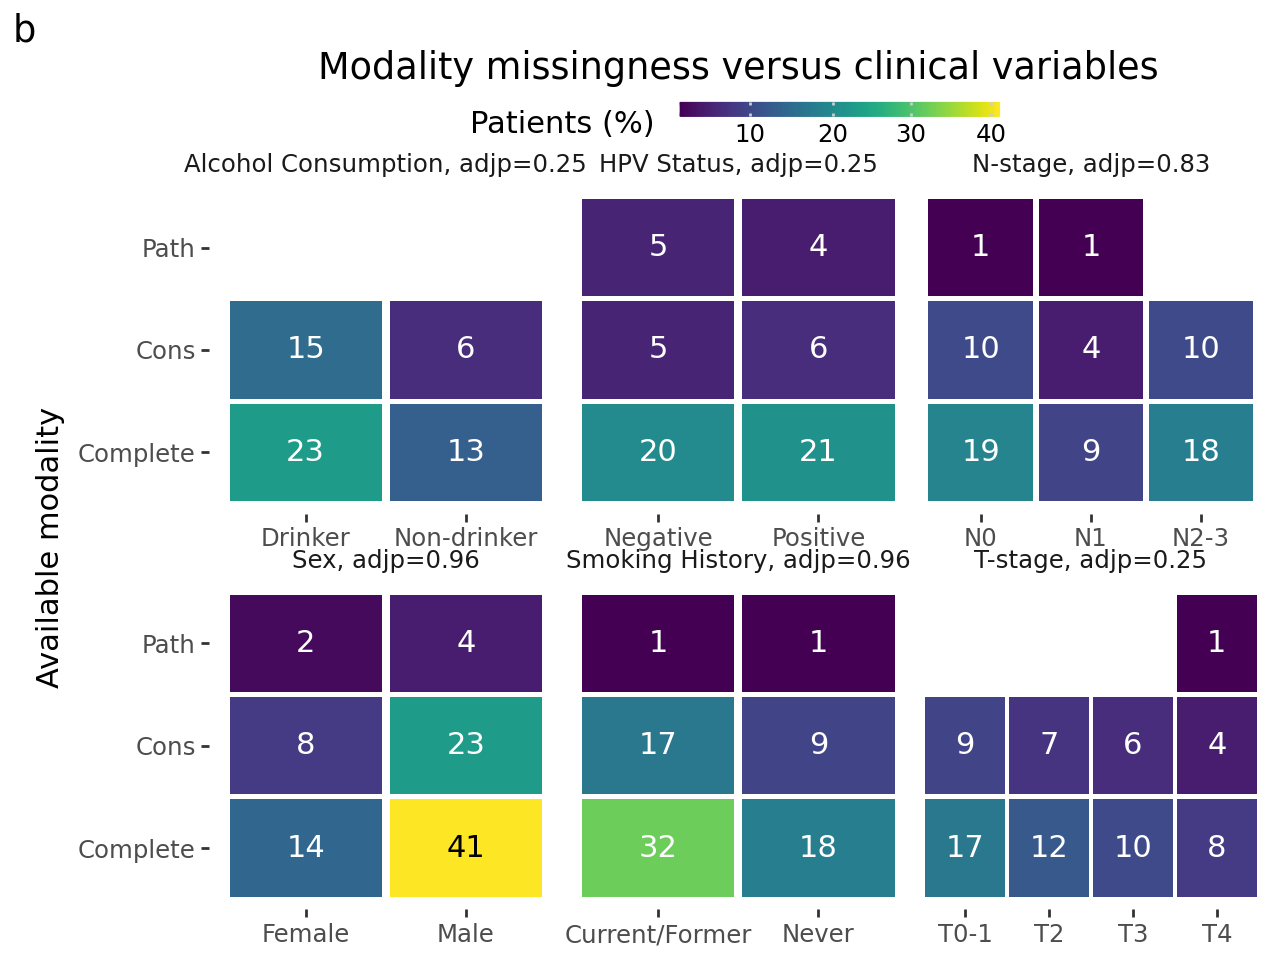

In [13]:
x,y = "Status", "Available"
facet_cols = "Column"
fill_by = "count"
color_by = "color"

clinical_data_with_clusters_to_show = pd.melt(
    clinical_data_with_clusters, 
    id_vars=y, 
    value_vars=discrete_clinical_variables, 
    var_name=facet_cols, 
    value_name=x
)
clinical_data_with_clusters_to_show = clinical_data_with_clusters_to_show.value_counts().reset_index()
clinical_data_with_clusters_to_show[fill_by] = np.ceil(clinical_data_with_clusters_to_show[fill_by].div(len(clinical_data_with_clusters)).mul(100)).astype(int)
clinical_data_with_clusters_to_show[color_by] = clinical_data_with_clusters_to_show[fill_by].gt(32)

ps = []
for var in discrete_clinical_variables:
    contingency_table = pd.crosstab(index=clinical_data_with_clusters[var], columns=clinical_data_with_clusters[y])
    p = chi2_contingency(contingency_table)[1]
    ps.append(p)
ps = multipletests(ps, method='fdr_bh')[1]
for var, p in zip(discrete_clinical_variables, ps):
    clinical_data_with_clusters_to_show[facet_cols] = clinical_data_with_clusters_to_show[facet_cols].replace(var, f"{var}, adjp={round(p,2)}")



p_mods_clin = (
    p9.ggplot(clinical_data_with_clusters_to_show, p9.aes(x=x, y=y, fill=fill_by))
    + p9.geom_tile(width = .95, height = .95)
    + p9.geom_text(p9.aes(label=fill_by, color=color_by), show_legend=False)
    + p9.facet_wrap(facet_cols, scales="free_x")
    + p9.theme_classic()
    + p9.scale_color_manual(["white", "black"])
    + p9.theme(strip_background=p9.element_blank(), legend_position="top", axis_title_x=p9.element_blank(),
               axis_line_y=p9.element_blank(), axis_line_x=p9.element_blank(), panel_spacing_x=0.0001, panel_spacing_y=0.01, legend_box_spacing=0.01)
    + p9.labs(x="", y="Available modality", tag="b", title="Modality missingness versus clinical variables", fill="Patients (%)")
    + p9.scale_fill_cmap(cmap_name='viridis', guide=p9.guide_colorbar(theme=p9.theme(legend_key_height=5)))
)
p_mods_clin

In [14]:
var_comp = "Available"
logrank_test_list = []
df_survival = []
for clinical_endpoint_idx, clinical_endpoint in enumerate(clinical_endpoints):
    t = clinical_endpoints[clinical_endpoint]["t"]
    e = clinical_endpoints[clinical_endpoint]["e"]
    description = clinical_endpoints[clinical_endpoint]["description"]
    clinical_data_endpoint = clinical_data_with_clusters[
        clinical_data_with_clusters[t].notna() &
        clinical_data_with_clusters[e].notna() &
        clinical_data_with_clusters[var_comp].notna()
        ]
    clinical_data_endpoint = clinical_data_endpoint.sort_values(by=t, ascending=False)
    clinical_data_endpoint = clinical_data_endpoint.drop_duplicates(subset='patient_id', keep='first')
    clinical_data_endpoint = clinical_data_endpoint.set_index("patient_id")

    clusters_for_var = clinical_data_endpoint[var_comp]

    logrank_test = multivariate_logrank_test(
        event_durations=clinical_data_endpoint[t],
        event_observed=clinical_data_endpoint[e],
        groups=clusters_for_var
    )
    
    logrank_test_list.append({"endpoint": description, "p": logrank_test.p_value})

    kmfs = []
    maxtime_list = []
    for label_id, label in enumerate(sorted(clusters_for_var.unique())):
        cl = (clusters_for_var == label)
        nn = len(clinical_data_endpoint[t][cl])
        ne = int(clinical_data_endpoint[e][cl].sum())
        kmf_cl = KaplanMeierFitter().fit(
            durations=clinical_data_endpoint[t][cl],
            event_observed=clinical_data_endpoint[e][cl],
            label=f"{label}"
        )
        kmfs.append(kmf_cl)
        maxtime_list.append(int(kmf_cl.timeline[-1].round()))
        
        kmf_cl_copy = copy.deepcopy(kmf_cl)
        km_df = kmf_cl_copy.survival_function_
        km_df.columns = ["Survival Probability"]
        cols = kmf_cl_copy.confidence_interval_.columns
        km_df['lower_ci'] = kmf_cl_copy.confidence_interval_[cols[0]]
        km_df['upper_ci'] = kmf_cl_copy.confidence_interval_[cols[1]]
        km_df[var_comp] = label
        km_df["endpoint"] = description
        km_df = km_df.reset_index(names="Time (months)")
        df_survival.append(km_df)


logrank_test_df = pd.DataFrame(logrank_test_list)
logrank_test_df["adjp"] = multipletests(logrank_test_df["p"], method='fdr_bh')[1]
logrank_test_df["sig"] = logrank_test_df["adjp"].lt(0.05)
logrank_test_df["adjp"] = "adjp = " + logrank_test_df["adjp"].round(3).astype(str)
logrank_test_df["x"] = 50
logrank_test_df["y"] = 0.55
logrank_test_df["endpoint"] = pd.Categorical(logrank_test_df["endpoint"], categories=clinical_endpoints_description, ordered=True)

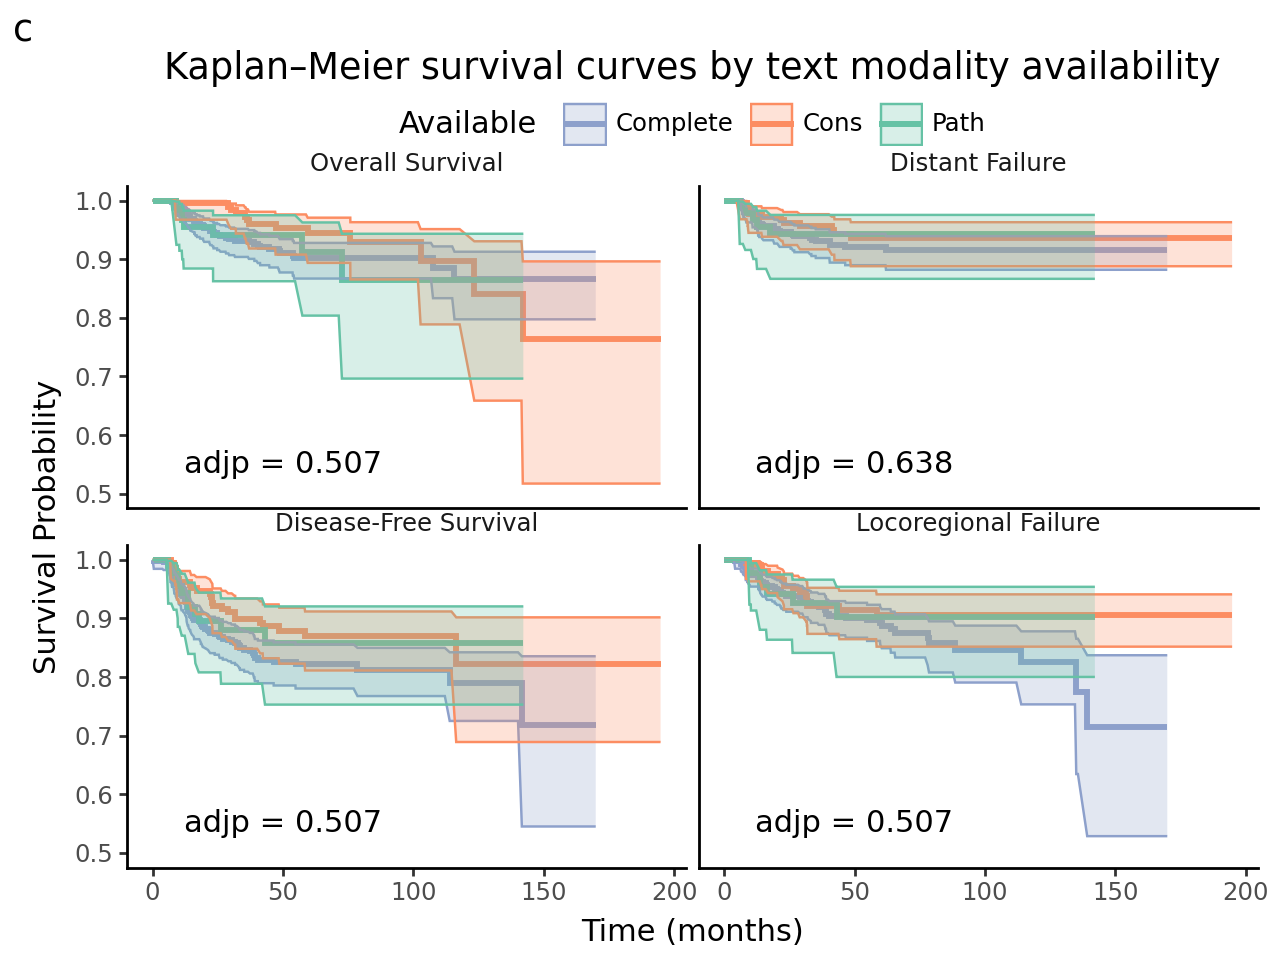

In [15]:
x,y = "Time (months)", "Survival Probability"
facet_cols = "endpoint"
fill_by = "Available"
plot_data = pd.concat(df_survival)
plot_data["endpoint"] = pd.Categorical(plot_data["endpoint"], categories=clinical_endpoints_description, ordered=True)

p_km = (
    p9.ggplot(plot_data, p9.aes(x=x, y=y, group=fill_by, fill=fill_by, color=fill_by))
    + p9.geom_step(size=1.2)
    + p9.geom_ribbon(p9.aes(ymin='lower_ci', ymax='upper_ci'), alpha=0.25)
    + p9.facet_wrap(facet_cols, ncol=2)
    + p9.geom_text(p9.aes(x="x", y="y", label="adjp"), data=logrank_test_df[logrank_test_df["sig"]], color="red", inherit_aes=False)
    + p9.geom_text(p9.aes(x="x", y="y", label="adjp"), data=logrank_test_df[~logrank_test_df["sig"]], color="black", inherit_aes=False)
    + p9.ylim(0.5, 1)
    + p9.theme_classic()
    + p9.theme(strip_background=p9.element_blank(), legend_position="top", legend_box_spacing=0.01)
    + p9.scale_fill_brewer(type="qualitative", palette="Set2", direction=-1)
    + p9.scale_color_brewer(type="qualitative", palette="Set2", direction=-1)
    + p9.labs(tag="c", title="Kaplan–Meier survival curves by text modality availability")
)
p_km

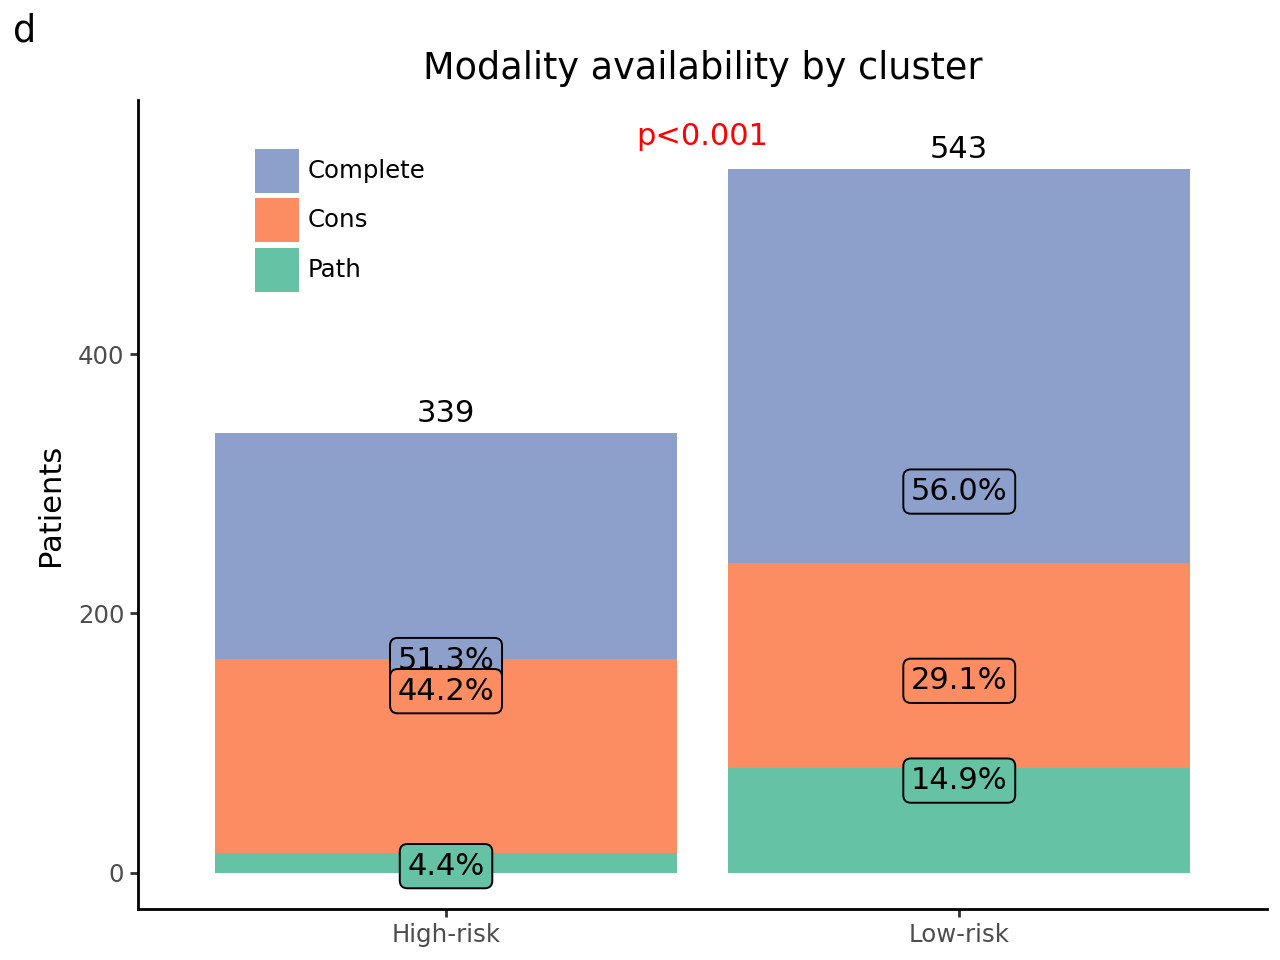

In [16]:
def prop_per_x(x, count):
    """
    Compute the proportion of the counts for each value of x
    """
    df = pd.DataFrame({"x": x, "count": count})
    prop = df["count"] / df.groupby("x")["count"].transform("sum")
    return prop
    

pd.testing.assert_index_equal(observed_mod_indicator.index, embedding_clusters.index)
to_plot = pd.concat([embedding_clusters, observed_mod_indicator.rename("Available")], axis=1)
contingency_table = pd.crosstab(index=to_plot[final_cluster_name], columns=to_plot["Available"])
p = chi2_contingency(contingency_table)[1]

p_cl_count = (
    p9.ggplot(to_plot, p9.aes(final_cluster_name, fill="Available"))
    + p9.geom_bar()
    + p9.geom_text(p9.aes(label=p9.after_stat("count"), group=1), stat="count", nudge_y=15)
    + p9.geom_label(p9.aes(label=p9.after_stat("prop_per_x(x, count) * 100"), y=p9.stage(after_stat="count", after_scale="y-10")),
                    stat="count", format_string="{:.1f}%", show_legend=False)
    + p9.theme_classic()
    + p9.theme(legend_position="inside", legend_position_inside=(0.12, 0.93), legend_title=p9.element_blank())
    + p9.scale_fill_brewer(type="qualitative", palette="Set2", direction=-1)
    + p9.annotate("text", x=1.5, y=to_plot[final_cluster_name].value_counts().iloc[0] + 25, label=f"p = {p:.3f}" if p > 0.001 else "p<0.001",
                  color="red" if p < 0.05 else "black")
    + p9.labs(y="Patients", x="", tag="d", title="Modality availability by cluster")
)
p_cl_count

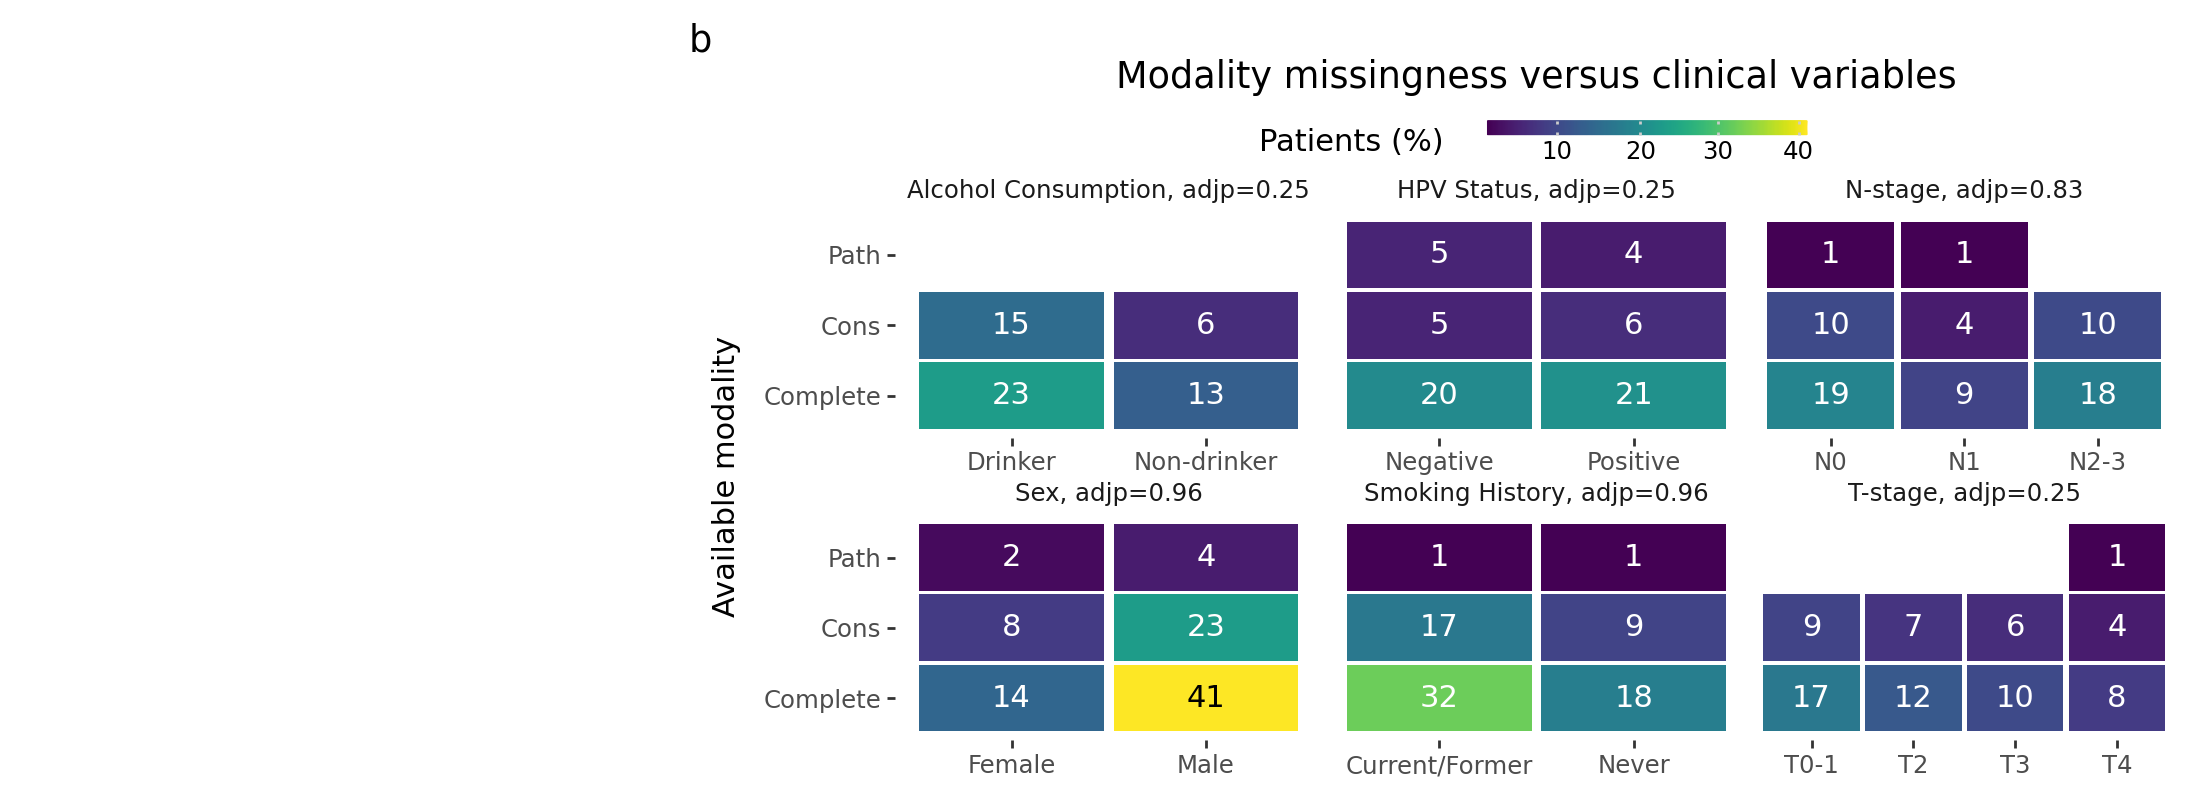

In [17]:
composition = (plot_spacer() | p_mods_clin + p9.theme(plot_margin_left=-0.27)) + p9.theme(figure_size=(11, 4))
composition

In [18]:
composition.save(os.path.join("figures", "Figure3b.svg"))

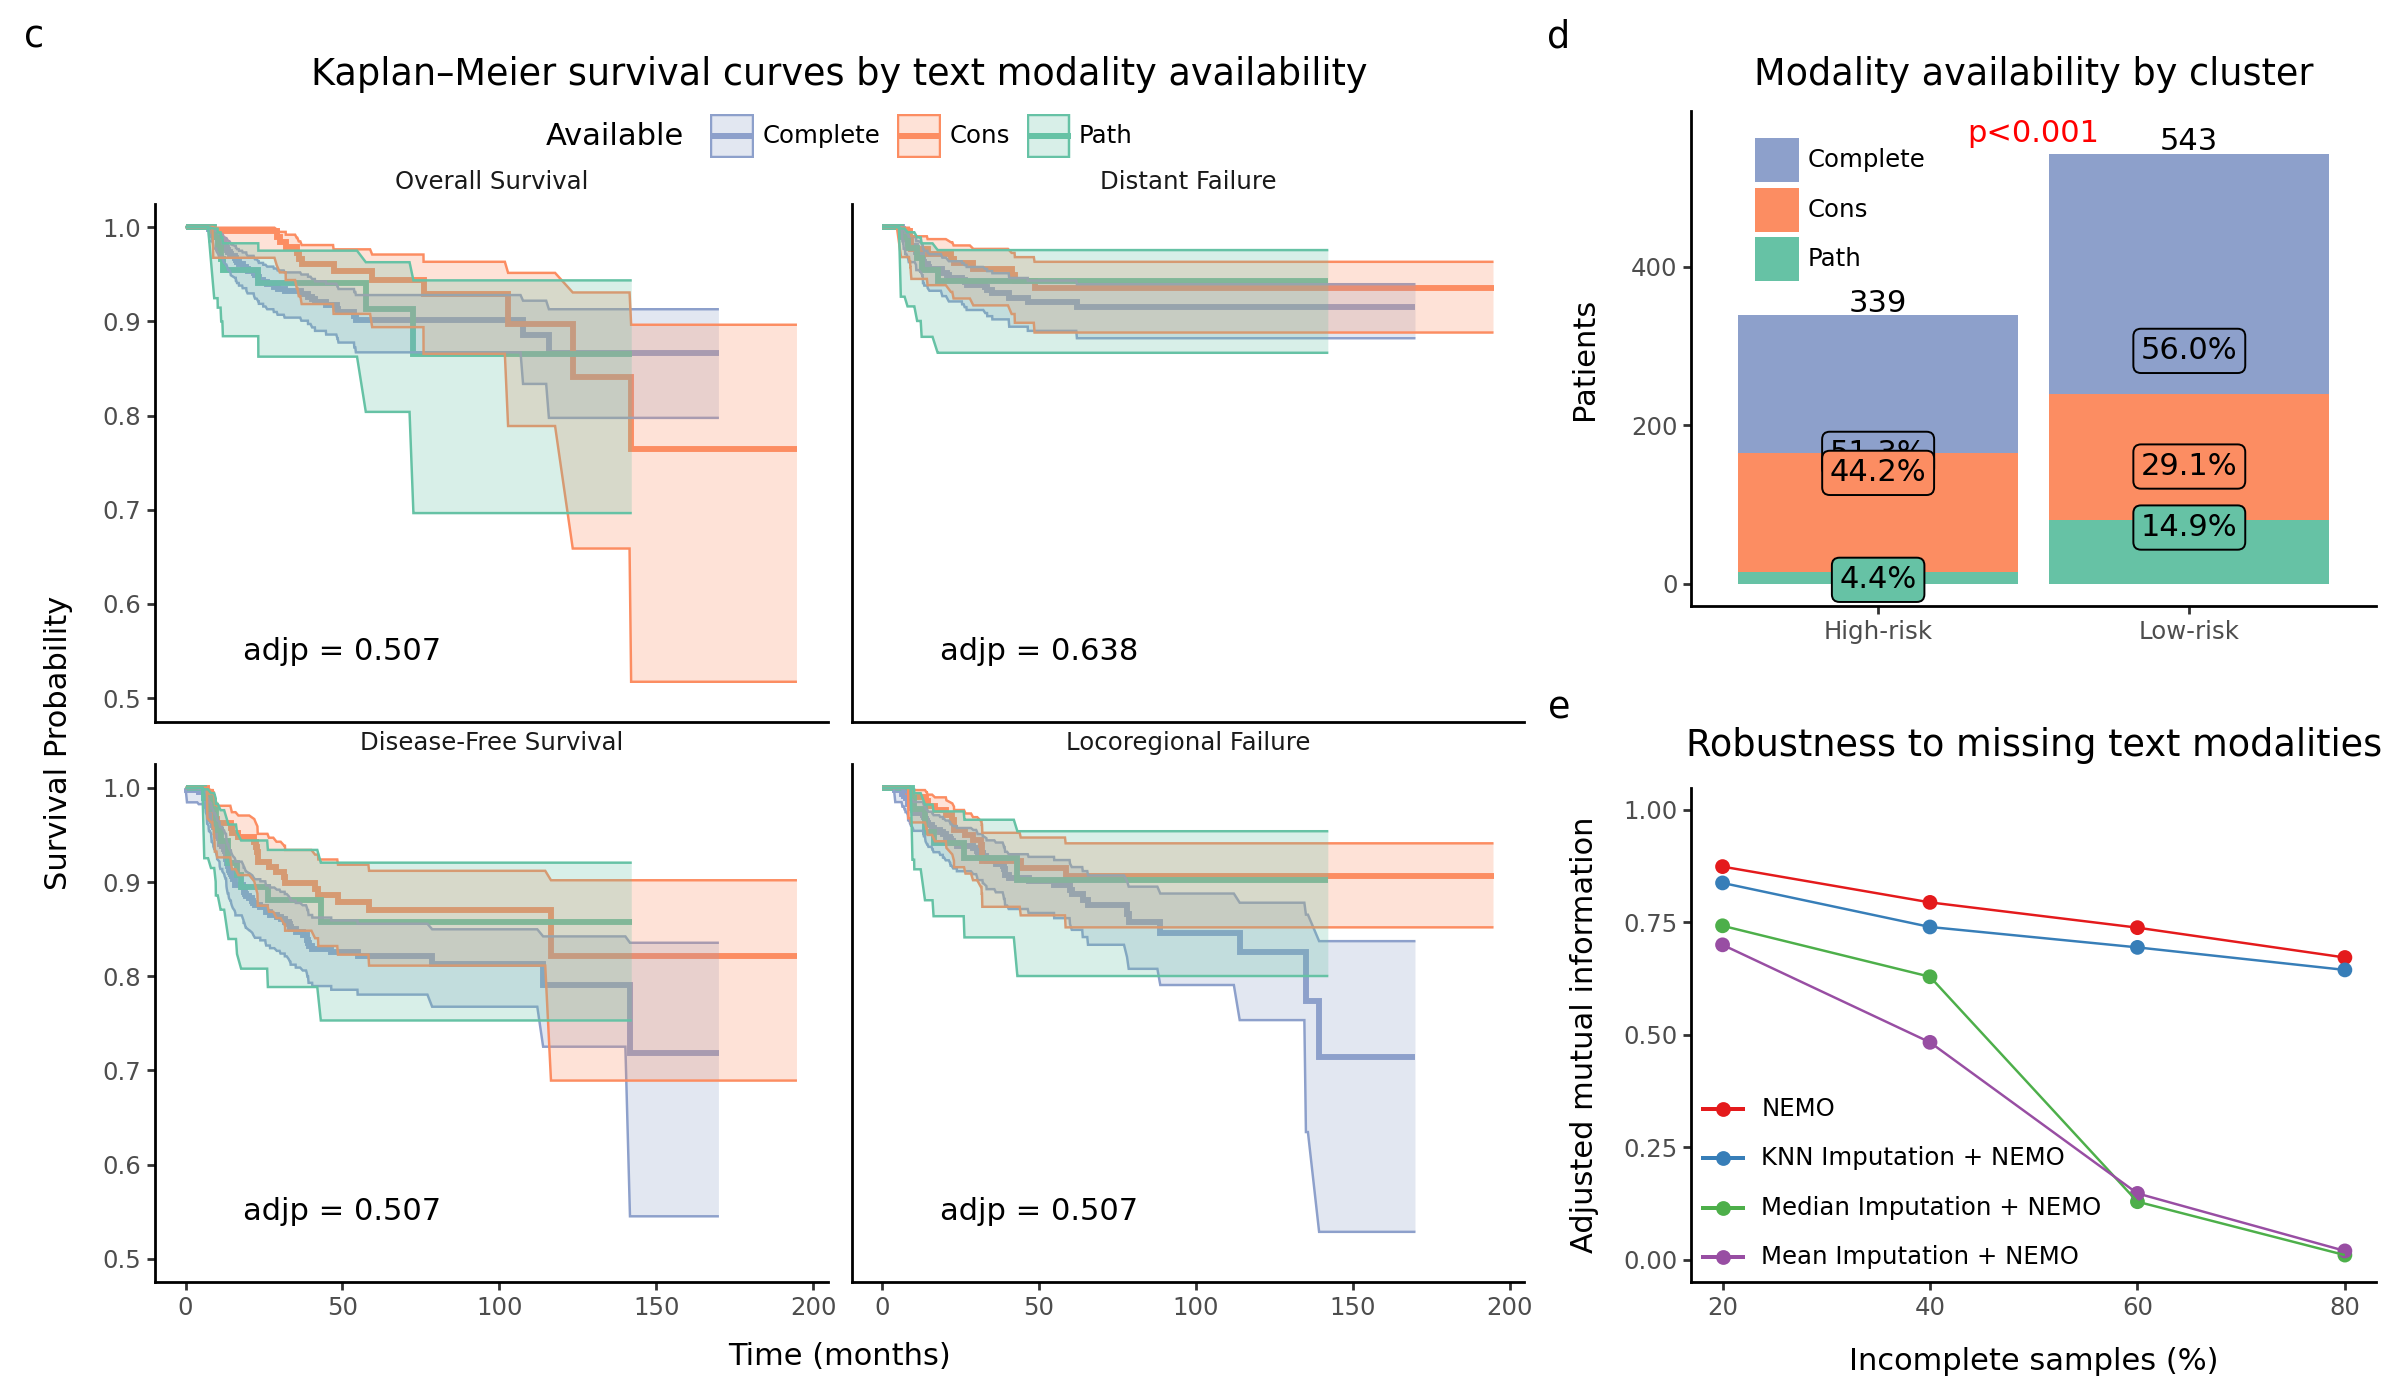

In [19]:
p_km_adjusted = p_km + p9.theme(plot_margin_right=-0.29)
composition = p_km_adjusted | (plot_spacer() | (p_cl_count / p_rob)) + p9.theme(figure_size=(12, 7))
composition

In [20]:
composition.save(os.path.join("figures", "Figure3c.svg"))